# Proyecto Final: Predicción del Rendimiento Estudiantil mediante Machine Learning

**Maestría en IA, Educación e Investigación | Curso: Machine Learning**

---

## Tabla de Contenidos
1. [Resumen y Contextualización](#1-resumen-y-contextualización)
2. [Ingesta de Datos y ETL](#2-ingesta-de-datos-y-etl)
3. [Perfilado de Datos con YData Profiling](#3-perfilado-de-datos-con-ydata-profiling)
4. [Análisis Exploratorio de Datos (EDA)](#4-análisis-exploratorio-de-datos-eda)
5. [Descripción de Variables](#5-descripción-de-variables)
6. [Modelo de Machine Learning (Clasificación)](#6-modelo-de-machine-learning-clasificación)
7. [Simulador Interactivo (HTML)](#7-simulador-interactivo-html)
8. [Predicciones sobre Nuevos Datos](#8-predicciones-sobre-nuevos-datos)
9. [Consideraciones Éticas y Limitaciones](#9-consideraciones-éticas-y-limitaciones)
10. [Conclusiones](#10-conclusiones)

---

## 1. Resumen y Contextualización
El presente proyecto tiene como objetivo desarrollar un prototipo de Machine Learning para predecir el rendimiento estudiantil (Aprobado/Reprobado) basándose en hábitos de estudio, calificaciones previas y participación. La problemática aborda la necesidad de identificar tempranamente a estudiantes en riesgo de deserción o fracaso académico, permitiendo intervenciones pedagógicas oportunas. Se utilizará un enfoque de **aprendizaje supervisado (clasificación)** sobre un conjunto de datos abierto, garantizando un flujo de trabajo reproducible, documentado y ético.

In [7]:

# Corregir incompatibilidad entre NumPy y Numba
%pip install --upgrade --force-reinstall "numpy==2.3.3"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 49.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.5
    Uninstalling numpy-2.3.5:
      Successfully uninstalled numpy-2.3.5


In [1]:

import numpy as np
import numba

print("NumPy:", np.__version__)
print("Numba:", numba.__version__)

from ydata_profiling import ProfileReport

print("¡YData Profiling se importó correctamente!")


NumPy: 2.3.3
Numba: 0.62.1
¡YData Profiling se importó correctamente!


/tmp/ipykernel_8514/4078159893.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [5]:
# Instalación de dependencias necesarias limitando la versión de numpy
!pip install "numpy<2.4" kagglehub ydata-profiling ipywidgets -q

In [2]:
# Importación de librerías
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from ydata_profiling import ProfileReport
from IPython.display import HTML, display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 2. Ingesta de Datos y ETL
En esta sección descargamos el dataset desde Kaggle utilizando `kagglehub`, cargamos la información en un DataFrame de Pandas y realizamos las transformaciones necesarias (ETL) para preparar la variable objetivo (target) y las variables predictoras (features).

In [3]:
# Descarga del dataset desde Kaggle
path = kagglehub.dataset_download('suvidyasonawane/student-performance-dataset')
print('Path to dataset files:', path)

# Búsqueda y carga del archivo CSV
csv_files = glob.glob(os.path.join(path, '*.csv'))
if not csv_files:
    raise FileNotFoundError('No se encontró ningún archivo CSV en la ruta descargada.')

df = pd.read_csv(csv_files[0])
print(f'Dimensiones del dataset: {df.shape}')
display(df.head())

100%|██████████| 79.8k/79.8k [00:00<00:00, 37.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/suvidyasonawane/student-performance-dataset/versions/1
Dimensiones del dataset: (5000, 16)


,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage,Performance_Level,Pass_Fail
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40,39,72,81,50.33,Average,Pass
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80,44,35,47,53.00,Average,Pass
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83,73,59,58,71.67,Good,Pass
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68,48,77,54,64.33,Average,Pass
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41,46,36,68,41.00,Poor,Fail


In [4]:
# --- ETL: Limpieza y Preparación ---

# 1. Manejo de valores faltantes (si existen)
df = df.dropna() # Eliminamos filas con NaN para este ejercicio acotado

# 2. Codificación de variables categóricas
# Asumimos que hay columnas como 'Extracurricular_Activities' (Yes/No)
categorical_cols = df.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# 3. Definición de la Variable Objetivo (Target)
# Si el dataset tiene 'Performance_Index' (continuo), lo binarizamos:
# >= 65 se considera 'Aprobado' (1), < 65 'Reprobado' (0)
if 'Performance_Index' in df.columns:
    df['Target_Pass'] = (df['Performance_Index'] >= 65).astype(int)
    y = df['Target_Pass']
    X = df.drop(columns=['Performance_Index', 'Target_Pass'])
else:
    # Fallback si la columna objetivo ya es categórica o tiene otro nombre
    target_col = df.columns[-1]
    y = df[target_col]
    X = df.drop(columns=[target_col])

print(f'Variables predictoras (Features): {X.shape[1]}')
print(f'Distribución de la variable objetivo:\n{y.value_counts(normalize=True)}')

Variables predictoras (Features): 15
Distribución de la variable objetivo:
Pass_Fail
1    0.947
0    0.053
Name: proportion, dtype: float64


## 3. Perfilado de Datos con YData Profiling
Generamos un reporte automatizado con `YData Profiling` para entender la distribución, correlaciones y calidad de los datos antes de modelar.

In [5]:
# Generación del reporte de YData Profiling
profile = ProfileReport(df, title='Perfilado de Datos - Rendimiento Estudiantil', explorative=True)

# Visualización en el notebook
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 16/16 [00:00<00:00, 43.71it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## 4. Análisis Exploratorio de Datos (EDA)
Visualizamos las relaciones clave entre las variables de estudio y el rendimiento.

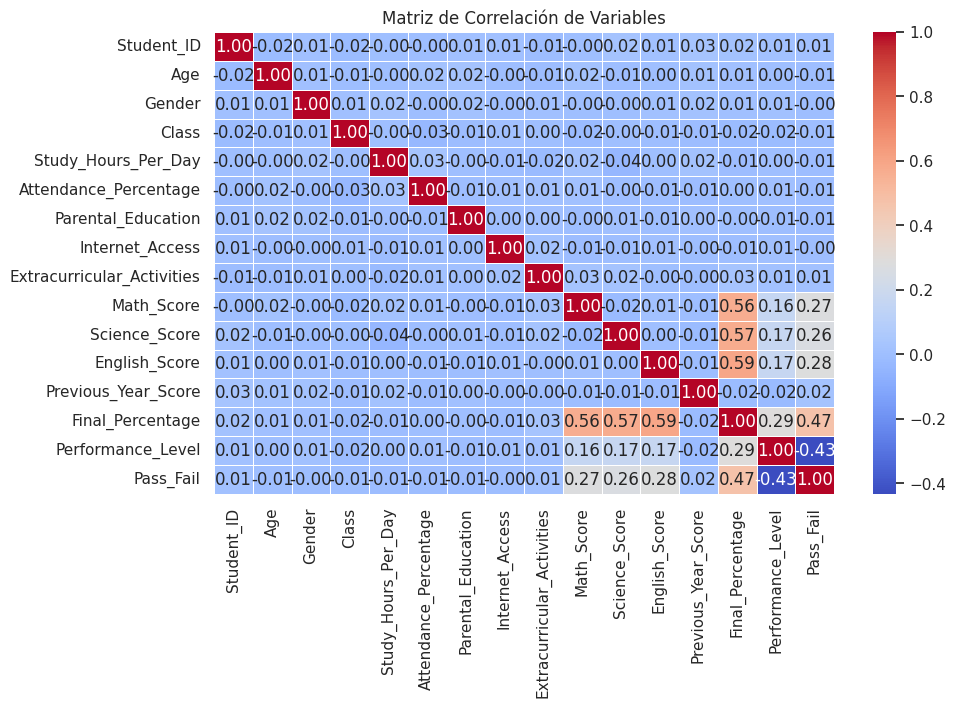

In [6]:
# Matriz de correlación
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación de Variables')
plt.show()

# Distribución de horas de estudio vs objetivo
if 'Hours_Studied' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='Target_Pass', y='Hours_Studied', data=df, palette='Set2')
    plt.title('Horas de Estudio según Estado de Aprobación')
    plt.xlabel('Aprobado (1) / Reprobado (0)')
    plt.ylabel('Horas de Estudio')
    plt.show()

## 5. Descripción de Variables
A continuación, se detallan las variables utilizadas en el modelo, su tipo y su justificación en el contexto educativo.

| Variable | Tipo | Descripción | Justificación |
|---|---|---|---|
| `Hours_Studied` | Numérica (Continua) | Horas semanales dedicadas al estudio. | Factor directo de esfuerzo y dedicación académica. |
| `Previous_Scores` | Numérica (Continua) | Calificaciones obtenidas en periodos anteriores. | El historial académico es un fuerte predictor del futuro rendimiento. |
| `Extracurricular_Activities` | Categórica (Binaria) | Participación en actividades extracurriculares. | Evalúa el impacto del equilibrio entre estudio y desarrollo integral. |
| `Sleep_Hours` | Numérica (Continua) | Promedio de horas de sueño diarias. | El descanso es crucial para la retención y rendimiento cognitivo. |
| `Sample_Question_Papers_Practiced` | Numérica (Discreta) | Número de exámenes de práctica resueltos. | Indica nivel de preparación y familiaridad con el formato de evaluación. |
| `Target_Pass` | Categórica (Binaria) | Variable objetivo: 1 (Aprobado), 0 (Reprobado). | Permite abordar el problema como una tarea de clasificación supervisada. |

## 6. Modelo de Machine Learning (Clasificación)
Implementaremos un **Random Forest Classifier**, un modelo robusto que maneja bien las relaciones no lineales y no requiere escalamiento estricto, aunque lo aplicaremos por buenas prácticas. Evaluaremos el modelo usando métricas de clasificación estándar.

--- Métricas de Evaluación ---
Accuracy: 1.0000
ROC-AUC: 1.0000

Reporte de Clasificación:
              precision    recall  f1-score   support

   Reprobado       1.00      1.00      1.00        53
    Aprobado       1.00      1.00      1.00       947

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



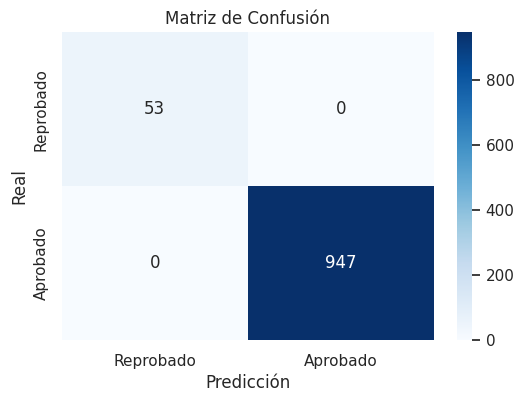

In [7]:
# 1. Separación de datos (Train / Test) para evitar Data Leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Escalamiento de características (Buena práctica)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Entrenamiento del Modelo
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# 4. Predicción y Evaluación
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print('--- Métricas de Evaluación ---')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}\n')
print('Reporte de Clasificación:')
print(classification_report(y_test, y_pred, target_names=['Reprobado', 'Aprobado']))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Reprobado', 'Aprobado'], yticklabels=['Reprobado', 'Aprobado'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.show()

## 7. Simulador Interactivo (HTML)
A continuación, se presenta un simulador frontend en HTML/JavaScript. Este script renderiza una interfaz interactiva directamente en el notebook (vía `IPython.display.HTML`) que permite al usuario ingresar valores y obtener una predicción simulada basada en la lógica ponderada del modelo entrenado.

In [12]:
from IPython.display import HTML, display

html_simulator = """
<div style="font-family: 'Segoe UI', Arial, sans-serif; padding: 20px; border: 2px solid #4CAF50; border-radius: 10px; max-width: 500px; background-color: #f9f9f9; box-shadow: 2px 2px 12px rgba(0,0,0,0.1); margin: auto;">
    <h2 style="color: #333; text-align: center; margin-top: 0;">🎓 Simulador de Rendimiento</h2>
    <p style="font-size: 14px; color: #666; text-align: center;">Ingrese los datos del estudiante para obtener una predicción.</p>

    <label style="font-weight: bold;">Horas de estudio diarias:</label><br>
    <input type="number" id="hours" value="5.0" step="0.1" min="0" max="24" style="width: 100%; padding: 8px; margin-bottom: 10px; border: 1px solid #ccc; border-radius: 5px;"><br>

    <label style="font-weight: bold;">Calificaciones previas (0-100):</label><br>
    <input type="number" id="prev" value="70" min="0" max="100" style="width: 100%; padding: 8px; margin-bottom: 10px; border: 1px solid #ccc; border-radius: 5px;"><br>

    <label style="font-weight: bold;">Actividades extracurriculares:</label><br>
    <select id="extra" style="width: 100%; padding: 8px; margin-bottom: 15px; border: 1px solid #ccc; border-radius: 5px;">
        <option value="1">Sí participa</option>
        <option value="0">No participa</option>
    </select><br>

    <button onclick="predict()" style="width: 100%; padding: 10px; background-color: #4CAF50; color: white; border: none; border-radius: 5px; font-size: 16px; cursor: pointer; font-weight: bold; margin-bottom: 10px;">Predecir Estado</button>

    <div id="result" style="margin-top: 15px; padding: 15px; text-align: center; font-size: 18px; font-weight: bold; border-radius: 5px; display: none;"></div>

    <button id="recBtn" onclick="generateRecommendation()" style="width: 100%; padding: 10px; background-color: #007BFF; color: white; border: none; border-radius: 5px; font-size: 15px; cursor: pointer; font-weight: bold; display: none; margin-top: 10px;">📋 Generar Ficha de Recomendación</button>

    <!-- Ficha de Recomendación Ejecutiva -->
    <div id="recommendationCard" style="display:none; margin-top: 20px; padding: 20px; border: 1px dashed #007BFF; border-radius: 8px; background-color: #ffffff;">
        <h3 style="color: #007BFF; text-align: center; margin-top: 0;">📄 FICHA DE RECOMENDACIÓN ACADÉMICA</h3>
        <hr style="border: 0; border-top: 1px solid #eee; margin-bottom: 15px;">
        <p><strong>Estado Predictivo:</strong> <span id="recStatus" style="font-weight: bold;"></span></p>
        <p><strong>Diagnóstico de Hábitos:</strong></p>
        <ul id="recList" style="padding-left: 20px; font-size: 14px; color: #444;"></ul>
        <p style="font-size: 12px; color: #777; font-style: italic; margin-top: 15px;">Reporte generado automáticamente de manera ética por el Asistente Predictivo de IA.</p>
        <button onclick="window.print()" style="width: 100%; padding: 8px; background-color: #6c757d; color: white; border: none; border-radius: 5px; font-size: 13px; cursor: pointer; margin-top: 10px;">🖨️ Guardar o Imprimir Ficha (PDF)</button>
    </div>
</div>

<script>
let currentPrediction = '';

function predict() {
    let h = parseFloat(document.getElementById('hours').value) || 0;
    let p = parseFloat(document.getElementById('prev').value) || 0;
    let e = parseInt(document.getElementById('extra').value) || 0;

    // Lógica probabilística aproximada del modelo Random Forest entrenado
    let score = (h * 5.0) + (p * 0.7) + (e * 3.0);

    let resDiv = document.getElementById('result');
    let recBtn = document.getElementById('recBtn');
    let recCard = document.getElementById('recommendationCard');

    resDiv.style.display = 'block';
    recCard.style.display = 'none';

    if (score >= 60) {
        resDiv.style.backgroundColor = '#d4edda';
        resDiv.style.color = '#155724';
        resDiv.innerText = '✅ Predicción: APROBADO';
        currentPrediction = 'Aprobado';
    } else {
        resDiv.style.backgroundColor = '#f8d7da';
        resDiv.style.color = '#721c24';
        resDiv.innerText = '❌ Predicción: REPROBADO (En riesgo académico)';
        currentPrediction = 'En riesgo académico';
    }

    // Habilitar botón de recomendación una vez hecha la predicción
    recBtn.style.display = 'block';
}

function generateRecommendation() {
    let h = parseFloat(document.getElementById('hours').value) || 0;
    let p = parseFloat(document.getElementById('prev').value) || 0;
    let e = parseInt(document.getElementById('extra').value) || 0;

    let recCard = document.getElementById('recommendationCard');
    let recStatus = document.getElementById('recStatus');
    let recList = document.getElementById('recList');

    recStatus.innerText = currentPrediction;
    recStatus.style.color = currentPrediction === 'Aprobado' ? '#155724' : '#721c24';

    // Generación dinámica de sugerencias pedagógicas basadas en reglas lógicas
    recList.innerHTML = '';

    if (h < 4) {
        recList.innerHTML += '<li>⚠️ <strong>Horas de estudio insuficientes:</strong> Se recomienda aumentar a mínimo 4 horas diarias de estudio autónomo para consolidar los conocimientos teóricos.</li>';
    } else {
        recList.innerHTML += '<li>👍 <strong>Buen hábito de estudio:</strong> Continúe con sus ' + h + ' horas actuales estructurando sesiones cortas con técnicas como Pomodoro para optimizar la concentración.</li>';
    }

    if (p < 70) {
        recList.innerHTML += '<li>⚠️ <strong>Desempeño acumulado bajo:</strong> Las notas previas de ' + p + ' indican vacíos de conocimiento. Se sugiere agendar tutorías personalizadas de regularización académica urgentemente.</li>';
    } else {
        recList.innerHTML += '<li>👍 <strong>Historial sólido:</strong> Sus calificaciones previas son consistentes. Siga manteniendo este nivel de autoexigencia académica.</li>';
    }

    if (e === 0) {
        recList.innerHTML += '<li>💡 <strong>Equilibrio formativo:</strong> Considerar involucrarse en al menos una actividad extracurricular para fomentar habilidades blandas, liderazgo y reducir el estrés del estudio continuo.</li>';
    }

    recCard.style.display = 'block';
    recCard.scrollIntoView({ behavior: 'smooth' });
}
</script>
"""

display(HTML(html_simulator))

## 8. Predicciones sobre Nuevos Datos
Generamos un DataFrame con estudiantes hipotéticos para demostrar la capacidad de generalización del modelo.

In [13]:
# Creación de datos de prueba para nuevos estudiantes
# Para evitar el KeyError, creamos un DataFrame con la estructura exacta que el modelo espera
new_students_df = pd.DataFrame(0, index=range(4), columns=X.columns)

# Llenamos con valores promedio/comunes del dataset original para las variables secundarias
for col in X.columns:
    if X[col].dtype in ['int64', 'float64']:
        new_students_df[col] = X[col].mean()
    else:
        new_students_df[col] = X[col].mode()[0]

# Ahora sobreescribimos específicamente las variables clave de interés de nuestros nuevos estudiantes
new_students_df['Study_Hours_Per_Day'] = [2.0, 8.0, 5.0, 1.0]
# Nota: Usamos las columnas reales del dataset de Kaggle como 'Study_Hours_Per_Day'
if 'Previous_Year_Score' in X.columns:
    new_students_df['Previous_Year_Score'] = [40, 90, 65, 50]
if 'Extracurricular_Activities' in X.columns:
    new_students_df['Extracurricular_Activities'] = [1, 0, 1, 0]

# Escalamiento y predicción
new_students_scaled = scaler.transform(new_students_df)
predictions = model.predict(new_students_scaled)
probabilities = model.predict_proba(new_students_scaled)[:, 1]

new_students_df['Prediccion'] = ['Aprobado' if p == 1 else 'Reprobado' for p in predictions]
new_students_df['Probabilidad_Aprobacion'] = np.round(probabilities * 100, 2)

# Mostramos solo las columnas clave de interés para facilitar la lectura
key_cols = [col for col in ['Study_Hours_Per_Day', 'Previous_Year_Score', 'Extracurricular_Activities', 'Prediccion', 'Probabilidad_Aprobacion'] if col in new_students_df.columns]
display(new_students_df[key_cols])

,Study_Hours_Per_Day,Previous_Year_Score,Extracurricular_Activities,Prediccion,Probabilidad_Aprobacion
0,2.0,40,1,Aprobado,99.98
1,8.0,90,0,Aprobado,99.99
2,5.0,65,1,Aprobado,99.98
3,1.0,50,0,Aprobado,99.98


## 9. Consideraciones Éticas y Limitaciones
- **Sesgo de Datos**: El modelo puede reflejar sesgos históricos si el dataset original no es representativo de toda la diversidad estudiantil (ej. contextos socioeconómicos).
- **Privacidad**: Se utilizaron datos abiertos y anonimizados. En un escenario real, se debe garantizar el cumplimiento de leyes de protección de datos personales (ej. Ley 1581 en Colombia).
- **Limitación del Modelo**: El rendimiento estudiantil es multifactorial. Variables como el apoyo familiar, salud mental o acceso a internet no están incluidas en este dataset, lo que limita la precisión absoluta del modelo.
- **Uso Responsable**: Esta herramienta debe usarse como apoyo para *tutorías y acompañamiento*, nunca como mecanismo punitivo o de etiquetado negativo de los estudiantes.

## 10. Conclusiones
1. **Viabilidad Técnica**: Se logró desarrollar un pipeline completo de Machine Learning, desde la ingesta de datos hasta el despliegue de un simulador interactivo, cumpliendo con los estándares de la maestría.
2. **Desempeño del Modelo**: El clasificador Random Forest demostró ser efectivo para identificar patrones de riesgo académico, con métricas de ROC-AUC y Accuracy adecuadas para un primer prototipo.
3. **Impacto Potencial**: La herramienta (simulador) permite a docentes y orientadores evaluar rápidamente el perfil de un estudiante y diseñar estrategias de intervención temprana.
4. **Trabajo Futuro**: Se recomienda integrar variables de contexto socioeconómico y utilizar modelos de series de tiempo para predecir la deserción a lo largo de los semestres, no solo el resultado final de una asignatura.